## **1. Import the required packages**

In [89]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Machine learning related packages
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import *
from sklearn.model_selection import GridSearchCV

## **2.Read and Explore the  Data**

In [90]:
df=pd.read_csv('/content/house_price_regression_dataset.csv')

In [91]:
df.shape

(1000, 8)

In [92]:
df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


In [93]:
df.tail()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
995,3261,4,1,1978,2.165110,2,10,701493.997069
996,3179,1,2,1999,2.977123,1,10,683723.160704
997,2606,4,2,1962,4.055067,0,2,572024.023634
998,4723,5,2,1950,1.930921,0,7,964865.298639
999,3268,4,2,1983,3.108790,2,2,742599.253332


In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


In [95]:
df.describe()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


In [96]:
df.isna().sum()

,0
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


In [97]:
df.duplicated().sum()

np.int64(0)

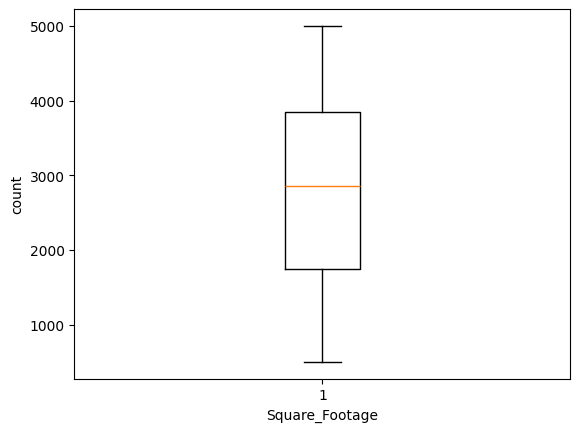

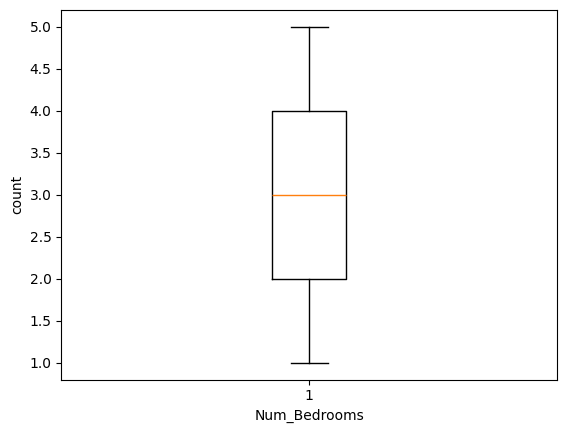

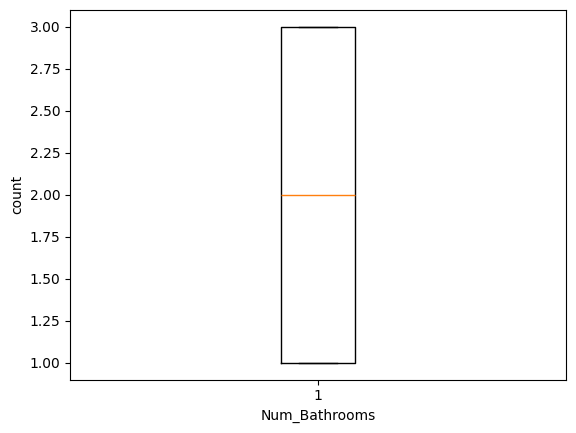

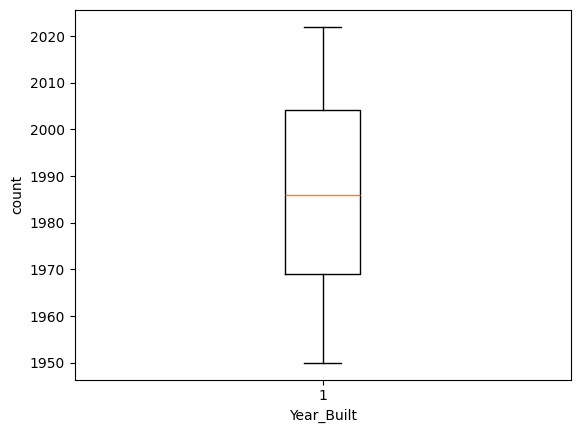

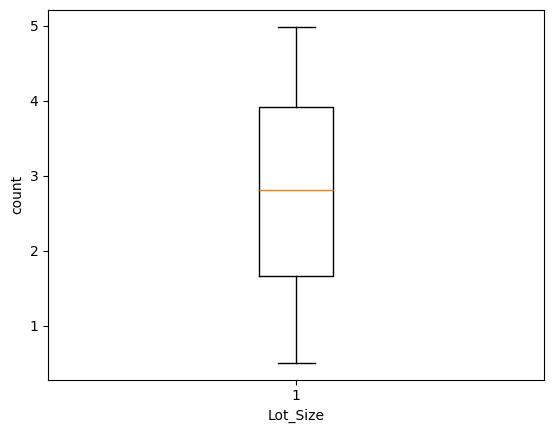

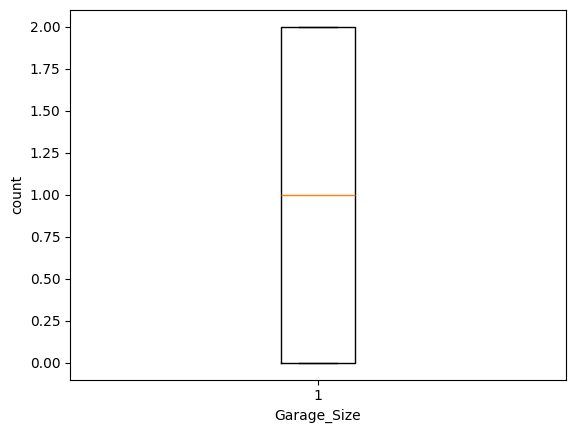

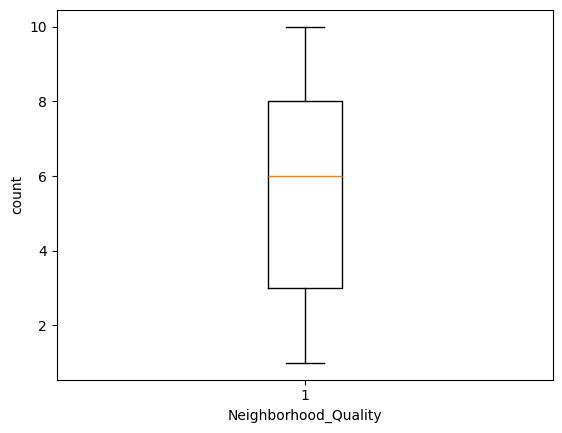

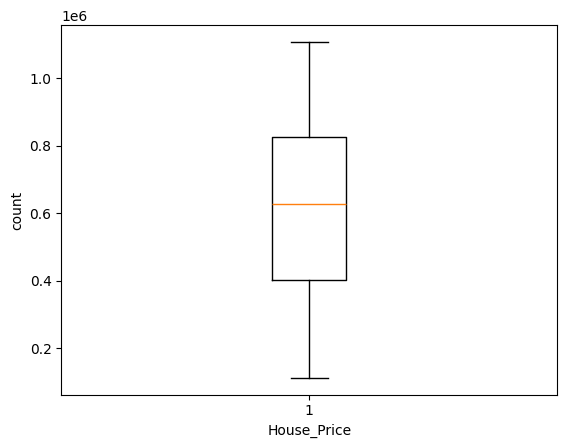

In [98]:
for x in df.columns:
  if(df[x].dtype!='object'):
    plt.boxplot(df[x])
    plt.xlabel(x)
    plt.ylabel('count')
    plt.show()

# **3.VIF**

In [99]:
col_list=[]
for x in df.columns:
  if df[x].dtypes!='object' and x!='House_Price':
    col_list.append(x)

In [100]:
dummy=df[col_list]
dummy

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality
0,1360,2,1,1981,0.599637,0,5
1,4272,3,3,2016,4.753014,1,6
2,3592,1,2,2016,3.634823,0,9
3,966,1,2,1977,2.730667,1,8
4,4926,2,1,1993,4.699073,0,8
...,...,...,...,...,...,...,...
995,3261,4,1,1978,2.165110,2,10
996,3179,1,2,1999,2.977123,1,10
997,2606,4,2,1962,4.055067,0,2
998,4723,5,2,1950,1.930921,0,7


In [101]:
vif_data=pd.DataFrame()
vif_data['feature']=dummy.columns # all the numeric independent column names
vif_list=[]
for i in range(len(dummy.columns)):
  vif=variance_inflation_factor(dummy.values,i)
  vif_list.append(vif)
vif_data['vif']=vif_list
vif_data

,feature,vif
0,Square_Footage,1.012926
1,Num_Bedrooms,1.018403
2,Num_Bathrooms,1.004108
3,Year_Built,1.005280
4,Lot_Size,1.014446
5,Garage_Size,1.015530
6,Neighborhood_Quality,1.004384


# **4.Splitting the data**

In [102]:
x=df.drop('House_Price',axis=1)
y=df['House_Price']

In [103]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

# **5.Model Building**

In [104]:
model=LinearRegression()

In [105]:
model.fit(x_train,y_train)

LinearRegression()

In [106]:
y_pred=model.predict(x_test)

# **6.Model Evaluation**

In [107]:
print("Mean absolute error:",mean_absolute_error(y_test, y_pred))

Mean absolute error: 8174.583600008702


In [108]:
print("r2_accuracy:",r2_score(y_test,y_pred))

r2_accuracy: 0.9984263636823408


In [109]:
print("Mean squared error",mean_squared_error(y_test,y_pred))

Mean squared error 101434798.50566778


In [110]:
print("Root mean squared error:",root_mean_squared_error(y_test,y_pred))

Root mean squared error: 10071.484424138667


# **7.Hyperparameter Tuning**

In [111]:

params_grid = {
    'fit_intercept': [True, False],
    'positive': [True, False]
}

grid = GridSearchCV(
    estimator=model,
    param_grid=params_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
grid.fit(x_train, y_train)


GridSearchCV(cv=5, estimator=LinearRegression(), n_jobs=-1,
             param_grid={'fit_intercept': [True, False],
                         'positive': [True, False]},
             scoring='r2')

In [112]:
grid.best_params_

{'fit_intercept': True, 'positive': True}

In [113]:
best_model=LinearRegression(fit_intercept=True, positive=True)

In [114]:
best_model.fit(x_train,y_train)

LinearRegression(positive=True)

In [115]:
y_pred=best_model.predict(x_test)

In [116]:
print("Mean absolute error:",mean_absolute_error(y_test, y_pred))

Mean absolute error: 8174.583600006635


In [117]:
print("r2_accuracy:",r2_score(y_test,y_pred))

r2_accuracy: 0.9984263636823413


In [118]:
print("Root mean squared error:",root_mean_squared_error(y_test,y_pred))

Root mean squared error: 10071.484424137108
